In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')


In [2]:
df = pd.read_csv('datasets/google_play_store/google_cleaned.csv')
df.head(2)

,Unnamed: 0,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Day,Month,Year
0,0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19000.0,10000.0,Free,0.0,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up,7,1,2018
1,1,Coloring book moana,ART_AND_DESIGN,3.9,967,14000.0,500000.0,Free,0.0,Everyone,Art & Design;Pretend Play,2018-01-15,2.0.0,4.0.3 and up,15,1,2018


In [3]:
df.drop('Unnamed: 0', axis=1, inplace=True)

In [4]:
df[df.duplicated('App')].shape

(1181, 16)

### Observations
The datasets has 1181 duplicate records

In [5]:
df.drop_duplicates(subset='App', keep='first', inplace=True)

In [6]:
df[df.duplicated('App')]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Day,Month,Year


In [7]:
df.shape

(9660, 16)

In [8]:
numeric_features = [feature for feature in df.columns if df[feature].dtype != 'O'] 
## '0' is Object type, so we are filtering out the numeric features from the dataset

categorical_features = [feature for feature in df.columns if df[feature].dtype == 'O']

print(f'We have {len(numeric_features)} numeric features : {numeric_features}')
print(f'We have {len(categorical_features)} categorical features : {categorical_features}')

We have 8 numeric features : ['Rating', 'Reviews', 'Size', 'Installs', 'Price', 'Day', 'Month', 'Year']
We have 8 categorical features : ['App', 'Category', 'Type', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']


In [9]:
for col in categorical_features:
    print(df[col].value_counts(normalize=True)*100)
    print('---------------------------------------')

App
iHoroscope - 2018 Daily Horoscope & Astrology         0.010352
Photo Editor & Candy Camera & Grid & ScrapBook        0.010352
Coloring book moana                                   0.010352
U Launcher Lite – FREE Live Cool Themes, Hide Apps    0.010352
Sketch - Draw & Paint                                 0.010352
                                                        ...   
Photo Designer - Write your name with shapes          0.010352
Learn To Draw Kawaii Characters                       0.010352
3D Color Pixel by Number - Sandbox Art Coloring       0.010352
Mandala Coloring Book                                 0.010352
Tattoo Name On My Photo Editor                        0.010352
Name: proportion, Length: 9660, dtype: float64
---------------------------------------
Category
FAMILY                 18.964803
GAME                    9.927536
TOOLS                   8.561077
BUSINESS                4.347826
MEDICAL                 4.089027
PERSONALIZATION         3.892340
PRODUCTIV

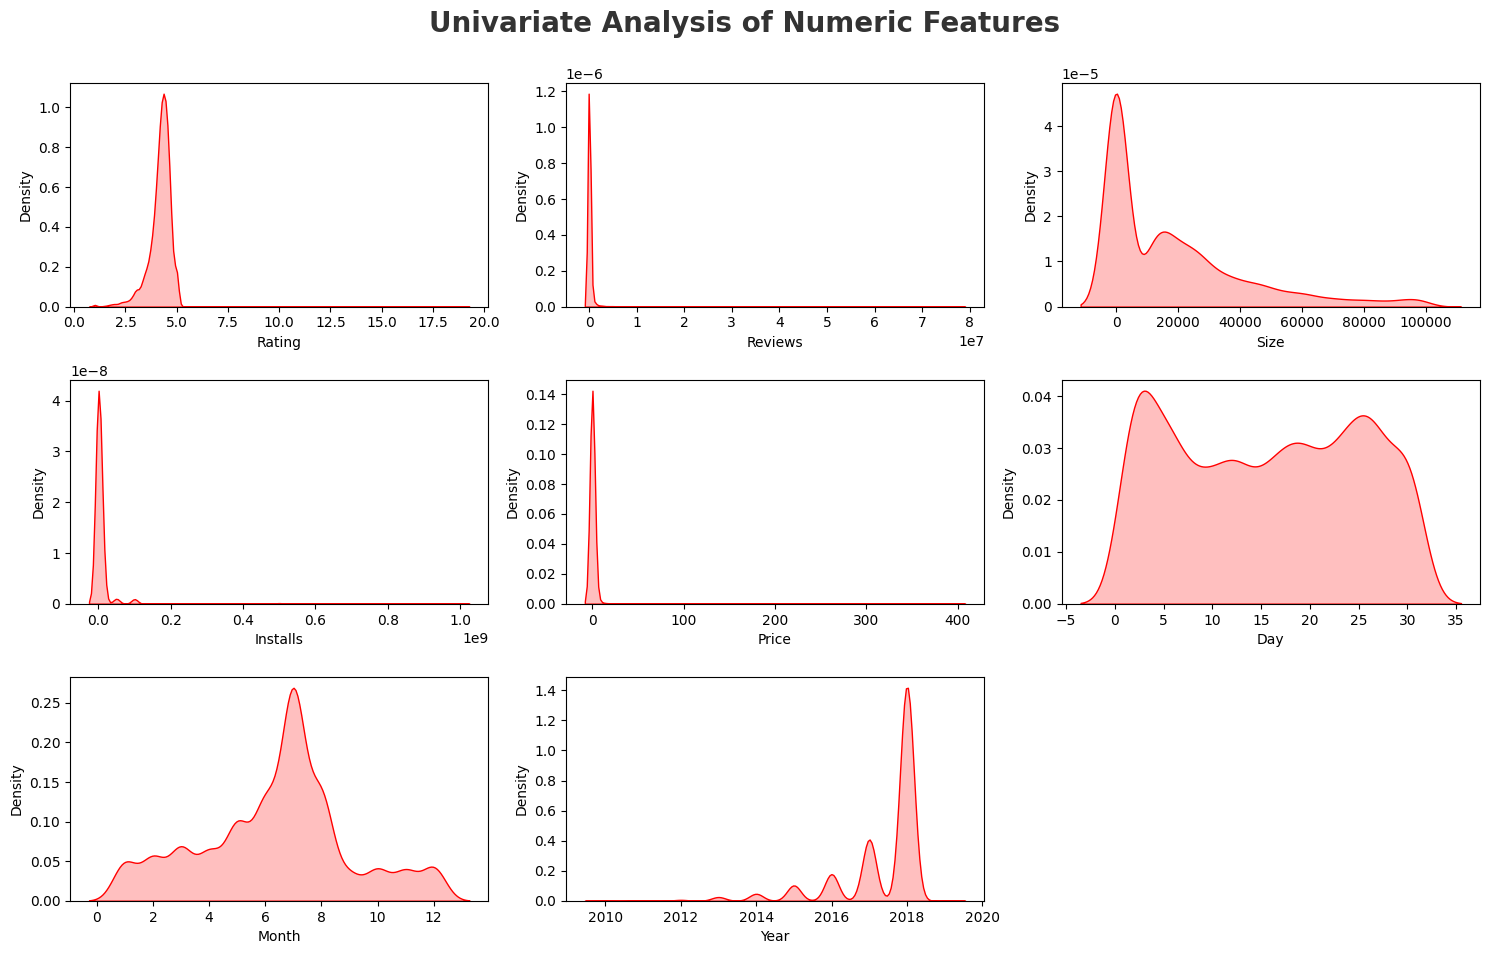

In [10]:
## Proportion of count data on numeric features
plt.figure(figsize=(15, 15))
plt.suptitle('Univariate Analysis of Numeric Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)

for i in range(len(numeric_features)):
    plt.subplot(5, 3, i+1)
    sns.kdeplot(x=df[numeric_features[i]], shade = True, color='r')
    plt.xlabel(numeric_features[i])
    plt.tight_layout()

### Observations:

* Year is left skewed
* Rating, installs, Price, Reviews and Size are Right Skewed

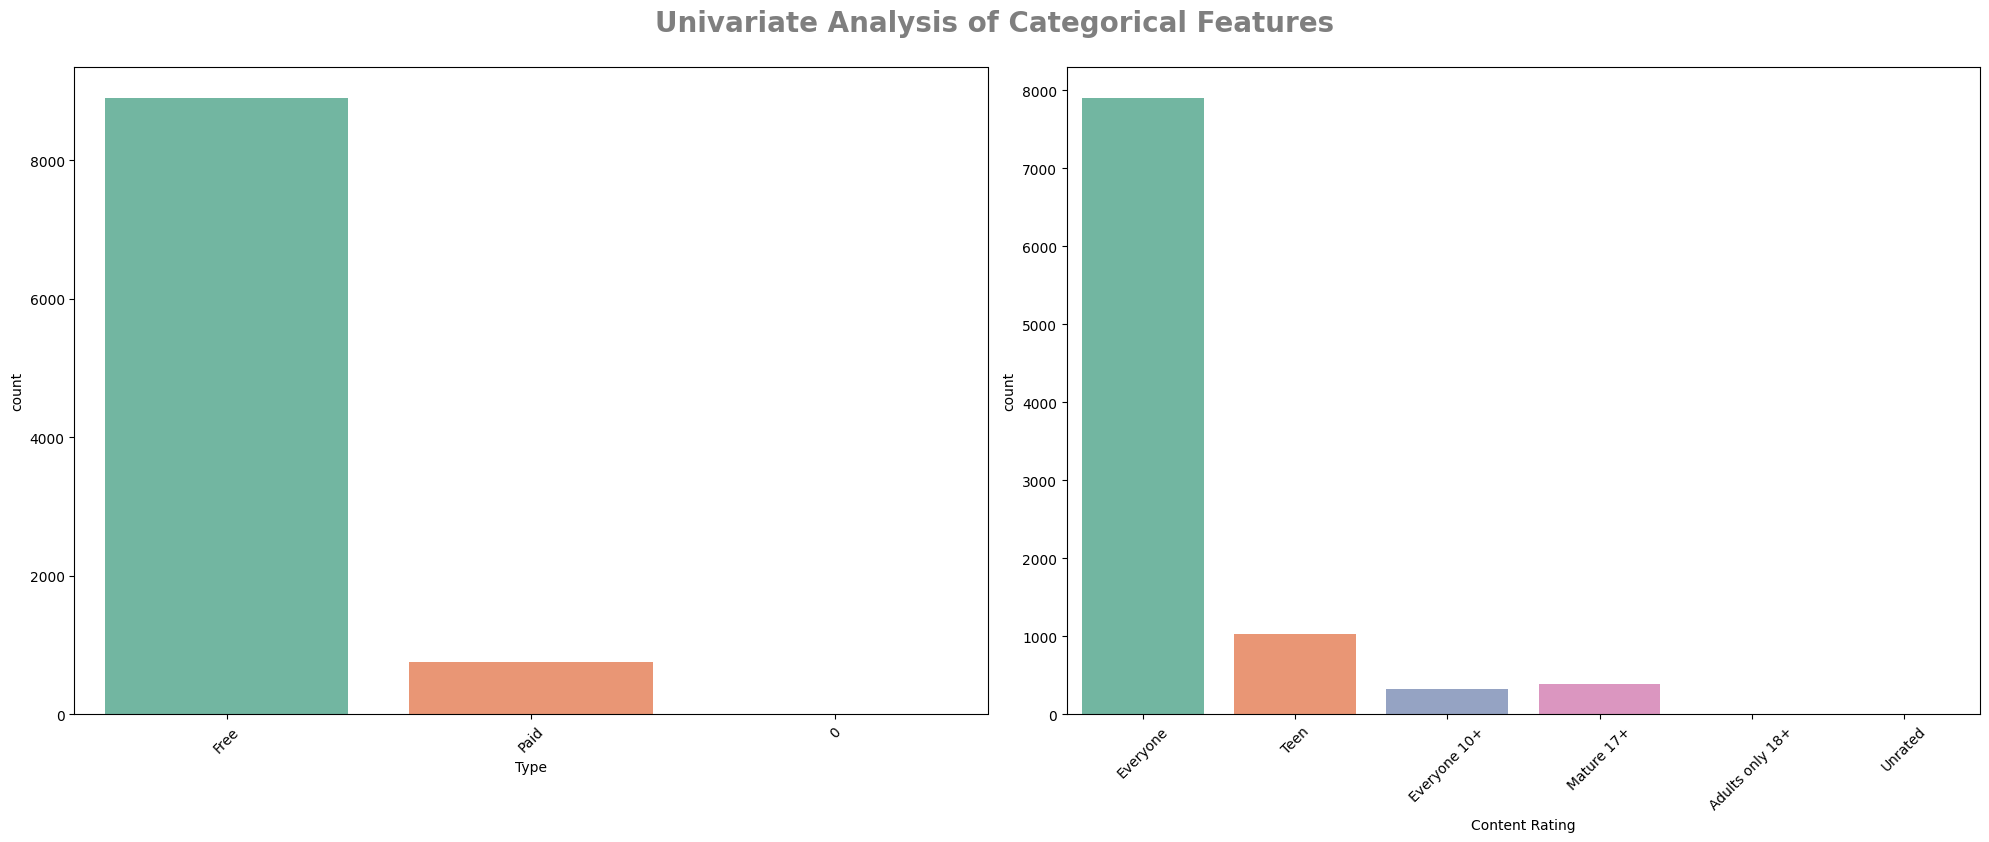

In [11]:
## Categorical Columns
plt.figure(figsize=(20, 15))
plt.suptitle('Univariate Analysis of Categorical Features', fontsize=20, fontweight='bold', alpha=0.5, y=1.)
category = ['Type', 'Content Rating']
for i in range(len(category)):
    plt.subplot(2, 2, i+1)
    sns.countplot(x=df[category[i]], palette='Set2')
    plt.xlabel(category[i])
    plt.xticks(rotation=45)
    plt.tight_layout()

### Which is the most popular app category?

<Axes: ylabel='count'>

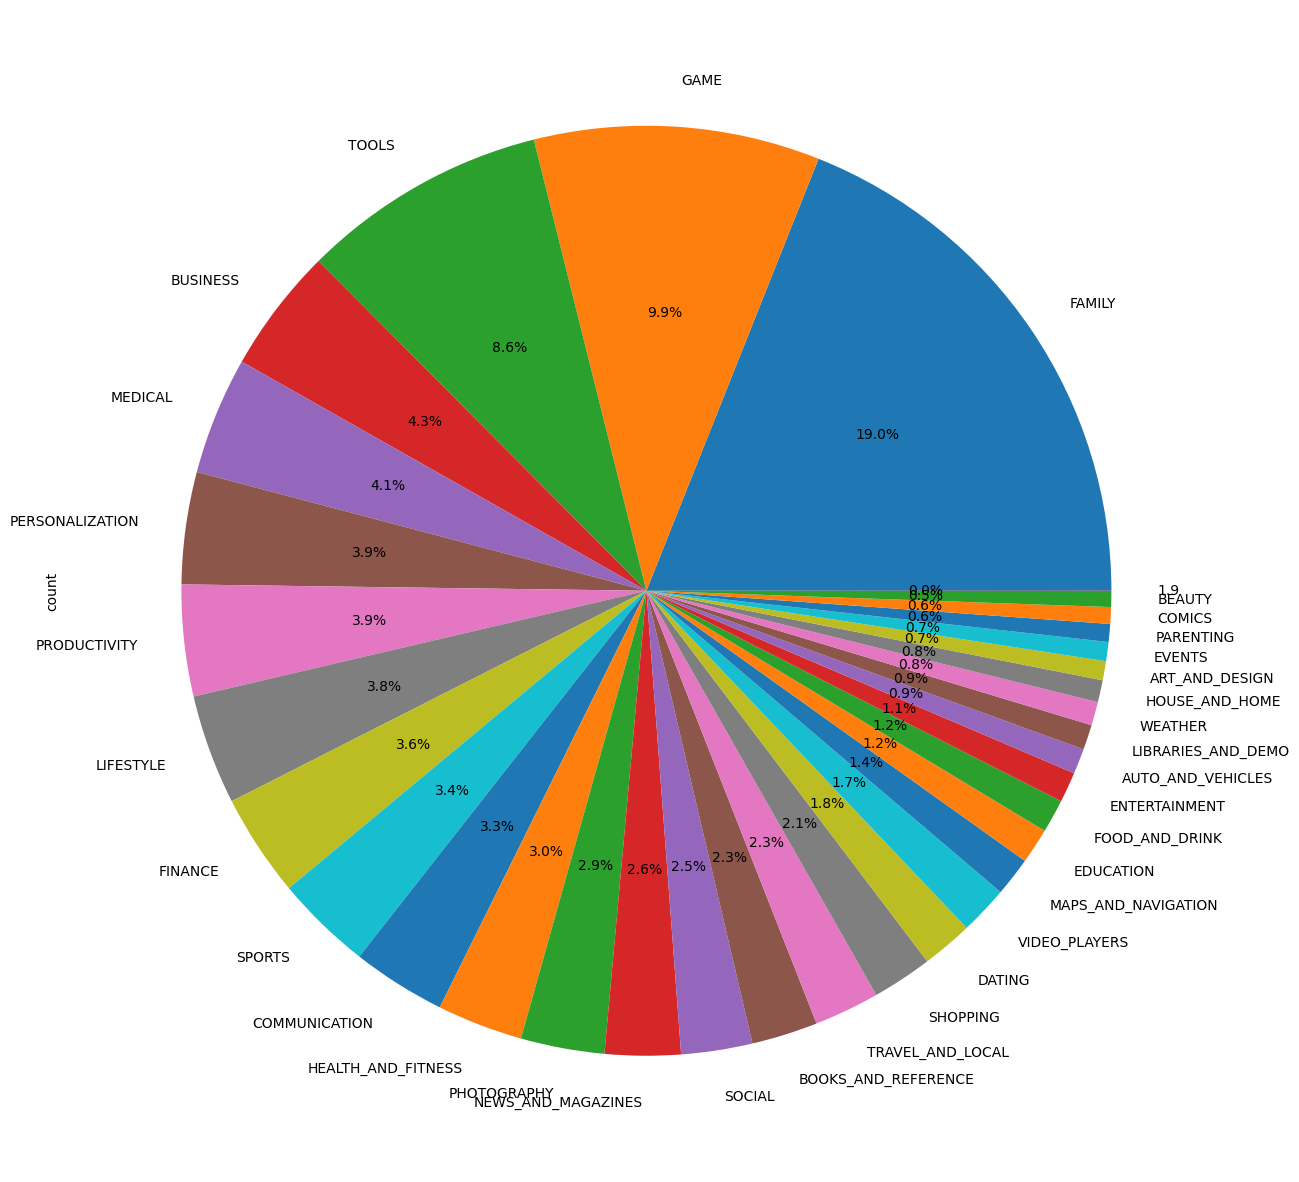

In [12]:
df['Category'].value_counts().plot.pie(y=df['Category'], figsize=(15, 16), autopct='%1.1f%%')

### Observation

In [13]:
category = pd.DataFrame(df['Category'].value_counts())
category.rename(columns={'Category':'Count'}, inplace=True)

In [14]:
category

,count
Category,
FAMILY,1832
GAME,959
TOOLS,827
BUSINESS,420
MEDICAL,395
PERSONALIZATION,376
PRODUCTIVITY,374
LIFESTYLE,369
FINANCE,345


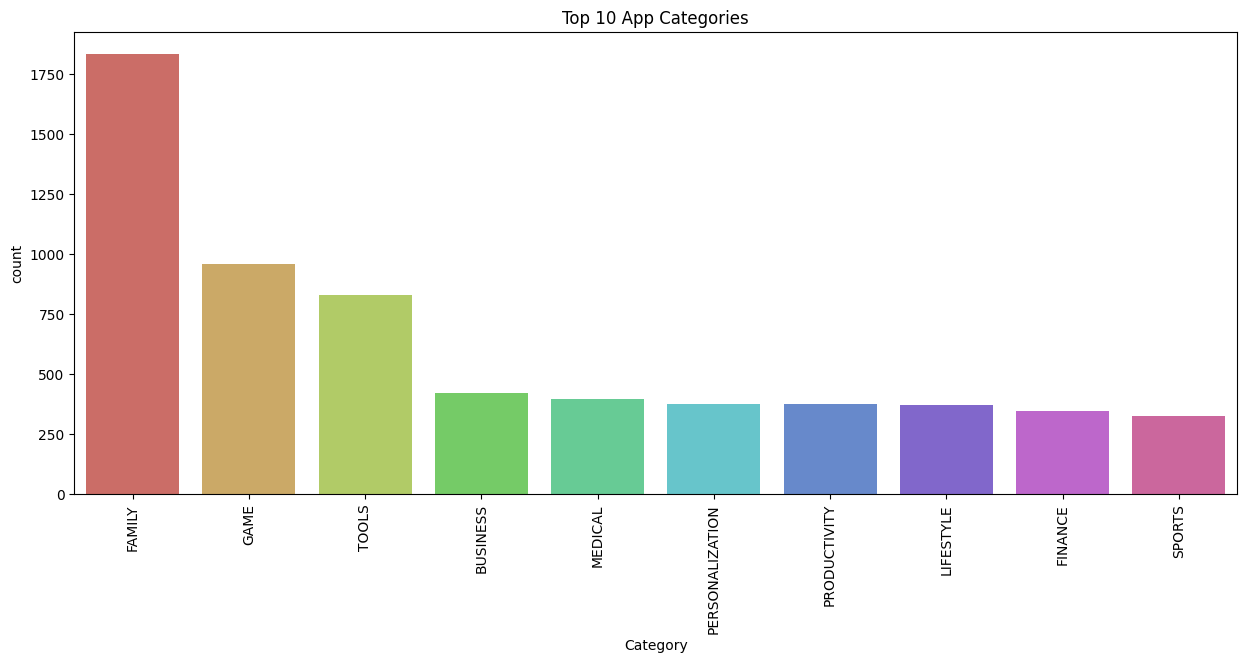

In [16]:
## Top 10 App
plt.figure(figsize=(15, 6))
sns.barplot(x=category.index[:10], y = 'count', data=category[:10], palette='hls')
plt.title('Top 10 App Categories')
plt.xticks(rotation=90)
plt.show()

## Internal Assignments

1. Which Category has largest number of installation?
2. What are the Top 5 most installed Apps in Each popular Categories?
3. How many apps are there on Goople Play Store which get 5 ratings?